In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/jessemostipak/hotel-booking-demand/hotel_bookings.csv


In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/jessemostipak/hotel-booking-demand/hotel_bookings.csv


In [3]:
import kagglehub

In [4]:
df = pd.read_csv('/kaggle/input/datasets/jessemostipak/hotel-booking-demand/hotel_bookings.csv')

In [5]:
df.shape

(119390, 32)

In [6]:
df.info

<bound method DataFrame.info of                hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27  

In [7]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [8]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


 Data Loading and Cleaning


In [9]:
df.isnull().sum().sort_values(ascending=False).head(10)

company                      112593
agent                         16340
country                         488
children                          4
arrival_date_month                0
arrival_date_week_number          0
hotel                             0
is_canceled                       0
stays_in_weekend_nights           0
arrival_date_day_of_month         0
dtype: int64

In [10]:
df[df['children'].isnull()]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40600,City Hotel,1,2,2015,August,32,3,1,0,2,...,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
40667,City Hotel,1,1,2015,August,32,5,0,2,2,...,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
40679,City Hotel,1,1,2015,August,32,5,0,2,3,...,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
41160,City Hotel,1,8,2015,August,33,13,2,5,2,...,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [11]:
df['children'] = df['children'].fillna(0)

In [12]:
df.isnull().sum().sort_values(ascending=False).head(10)

company                     112593
agent                        16340
country                        488
hotel                            0
arrival_date_month               0
arrival_date_week_number         0
lead_time                        0
is_canceled                      0
stays_in_weekend_nights          0
stays_in_week_nights             0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(31994)

In [14]:
df.shape

(119390, 32)

In [15]:
df = df.drop_duplicates()

In [16]:
print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (87396, 32)
Remaining duplicate rows: 0


In [17]:
df = df.copy()

df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date']
)

In [18]:
df['reservation_status_date'].dtype

dtype('<M8[ns]')

In [19]:
print("Dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())
print("Missing children:", df['children'].isnull().sum())

Dataset shape: (87396, 32)
Remaining duplicates: 0
Missing children: 0


**Average Lead Time for Bookings**

In [20]:
df['lead_time'].mean()

np.float64(79.89136802599661)

In [21]:
print("Average booking lead time:", round(df['lead_time'].mean(), 2), "days")

Average booking lead time: 79.89 days


**Booking Distribution by Hotel Type**

In [22]:
df['hotel'].value_counts()


hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

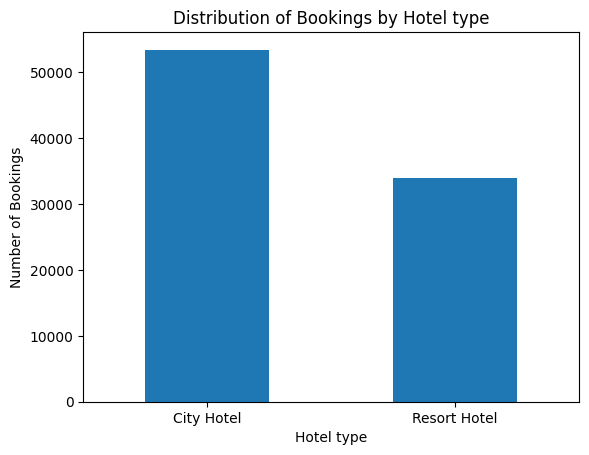

In [23]:
import matplotlib.pyplot as plt

df['hotel'].value_counts().plot(kind='bar')

plt.title('Distribution of Bookings by Hotel type')
plt.xlabel('Hotel type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=0)
plt.show()

Booking Cancellation Rate

In [24]:
df['is_canceled'].sum()

np.int64(24025)

In [25]:
canceled = df['is_canceled'].sum()
total = len(df)

print("Total bookings:", total)
print("Canceled bookings:", canceled)
print("Cancellation rate:", round(canceled / total * 100, 2), "%")

Total bookings: 87396
Canceled bookings: 24025
Cancellation rate: 27.49 %


**Most Common Arrival Month**

In [26]:
df['arrival_date_month'].value_counts()

arrival_date_month
August       11257
July         10057
May           8355
April         7908
June          7765
March         7513
October       6934
September     6690
February      6098
December      5131
November      4995
January       4693
Name: count, dtype: int64

In [27]:
df['arrival_date_month'].value_counts().idxmax()

'August'

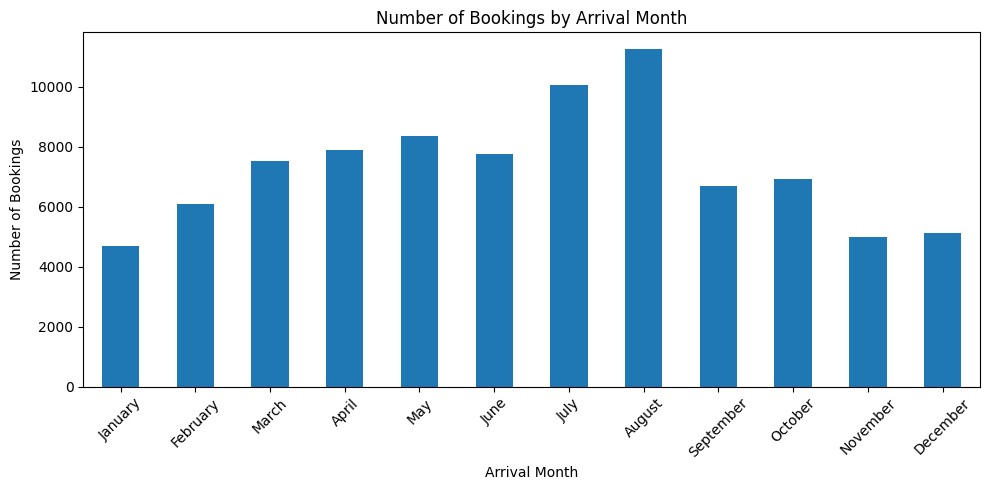

In [28]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings = df['arrival_date_month'].value_counts().reindex(month_order)

monthly_bookings.plot(kind='bar', figsize=(10, 5))

plt.title('Number of Bookings by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Average Number of Special Requests**

In [29]:
print(
    "Average special requests per booking:",
    round(df['total_of_special_requests'].mean(), 2)
)

Average special requests per booking: 0.7


**Country with the Highest Number of Bookings**

In [30]:
df['country'].value_counts()

country
PRT    27453
GBR    10433
FRA     8837
ESP     7252
DEU     5387
       ...  
MRT        1
KIR        1
SDN        1
ATF        1
SLE        1
Name: count, Length: 177, dtype: int64

In [31]:
df['country'].value_counts().idxmax()

'PRT'

In [32]:
df['country'].value_counts().max()

27453

**Average ADR by Hotel Type**

In [33]:
df.groupby('hotel')['adr'].mean()

hotel
City Hotel      110.985944
Resort Hotel     99.025346
Name: adr, dtype: float64

In [34]:
print(
    df.groupby('hotel')['adr']
    .mean()
    .round(2)
)

hotel
City Hotel      110.99
Resort Hotel     99.03
Name: adr, dtype: float64


**Bookings Requiring Parking Spaces**

In [35]:
parking_bookings = (df['required_car_parking_spaces'] > 0).sum()

total_bookings = len(df)

parking_percentage = (parking_bookings / total_bookings) * 100

print("Bookings requiring parking:", parking_bookings)
print("Total bookings:", total_bookings)
print("Percentage requiring parking:", round(parking_percentage, 2), "%")

Bookings requiring parking: 7313
Total bookings: 87396
Percentage requiring parking: 8.37 %


**Average Length of Stay**

In [36]:
print(
    "Average week nights:",
    round(df['stays_in_week_nights'].mean(), 2)
)

print(
    "Average weekend nights:",
    round(df['stays_in_weekend_nights'].mean(), 2)
)

Average week nights: 2.63
Average weekend nights: 1.01


In [37]:
df['total_stay_nights'] = (
    df['stays_in_week_nights']
    + df['stays_in_weekend_nights']
)

print(
    "Average total stay duration:",
    round(df['total_stay_nights'].mean(), 2),
    "nights"
)

Average total stay duration: 3.63 nights


**Bookings with an Agent ID**

In [38]:
df['agent'].count()

np.int64(75203)

In [39]:
agent_bookings = df['agent'].count()
total_bookings = len(df)

print("Bookings with an agent ID:", agent_bookings)
print(
    "Percentage with an agent ID:",
    round(agent_bookings / total_bookings * 100, 2),
    "%"
)

Bookings with an agent ID: 75203
Percentage with an agent ID: 86.05 %


**Cancellation Rate by Hotel Type**

In [40]:
df.groupby('hotel')['is_canceled'].mean().mul(100).round(2)

hotel
City Hotel      30.04
Resort Hotel    23.48
Name: is_canceled, dtype: float64

**Average ADR by Market Segment**

In [41]:
df.groupby('market_segment')['adr'].mean().round(2).sort_values(ascending=False)

market_segment
Online TA        118.17
Direct           116.58
Aviation         100.17
Offline TA/TO     81.76
Groups            74.86
Corporate         68.15
Undefined         15.00
Complementary      3.05
Name: adr, dtype: float64

**Lead Time and Booking Cancellations**

In [42]:
df.groupby('is_canceled')['lead_time'].mean().round(2)

is_canceled
0     70.10
1    105.72
Name: lead_time, dtype: float64

**Booking Count by Distribution Channel**

In [43]:
df['distribution_channel'].value_counts()

distribution_channel
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64

**Previous Cancellations by Hotel Type**

In [44]:
df.groupby('hotel')['previous_cancellations'].mean().round(2)

hotel
City Hotel      0.04
Resort Hotel    0.02
Name: previous_cancellations, dtype: float64

**Average ADR Trend Across Years**

In [45]:
df.groupby('arrival_date_year')['adr'].mean().round(2)

arrival_date_year
2015     92.16
2016    101.54
2017    118.71
Name: adr, dtype: float64

<Axes: title={'center': 'Average ADR by Arrival Year'}, xlabel='Arrival Year', ylabel='Average ADR'>

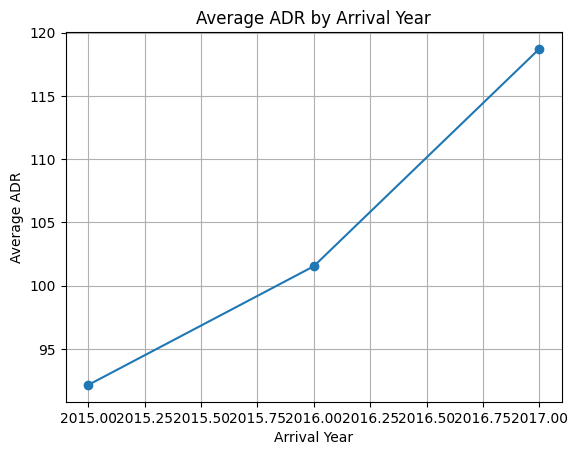

In [46]:
adr_by_year = df.groupby('arrival_date_year')['adr'].mean()

adr_by_year.plot(
    kind='line',
    marker='o',
    title='Average ADR by Arrival Year',
    xlabel='Arrival Year',
    ylabel='Average ADR',
    grid=True
)

**Monthly Summed ADR**

In [47]:
df.groupby('arrival_date_month')['adr'].sum().sort_values(ascending=False)

arrival_date_month
August       1698412.48
July         1363146.03
June          929859.68
May           929040.10
April         819368.35
September     749823.65
October       625117.56
March         613132.35
February      455472.02
December      417921.11
November      363408.53
January       328748.13
Name: adr, dtype: float64

**Special Requests and Average ADR**

In [48]:
df.groupby('total_of_special_requests')['adr'].mean().round(2)

total_of_special_requests
0     99.67
1    109.65
2    118.57
3    125.07
4    131.09
5    129.98
Name: adr, dtype: float64

**Stay Duration by Guest Type**

In [49]:
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

df.groupby('is_repeated_guest')['total_nights'].mean().round(2)

is_repeated_guest
0    3.70
1    1.93
Name: total_nights, dtype: float64

**Most Popular Reserved Room Type**

In [50]:
df['reserved_room_type'].value_counts()

reserved_room_type
A    56552
D    17398
E     6049
F     2823
G     2052
B      999
C      915
H      596
L        6
P        6
Name: count, dtype: int64

In [51]:
import pandas as pd
import statsmodels.api as sm

**Factors Associated with Booking Cancellations**

In [52]:
X = df[['lead_time', 'booking_changes', 'total_of_special_requests']]
y = df['is_canceled']

In [53]:
X = sm.add_constant(X)

model = sm.Logit(y, X).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.555845
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            is_canceled   No. Observations:                87396
Model:                          Logit   Df Residuals:                    87392
Method:                           MLE   Df Model:                            3
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                 0.05480
Time:                        18:13:04   Log-Likelihood:                -48579.
converged:                       True   LL-Null:                       -51395.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                        -1.0442      0.013    -83.123      0.000      -1.

**Guest Composition and ADR**

In [54]:
import statsmodels.api as sm

X = df[['adults', 'children', 'babies']]
y = df['adr']

X = sm.add_constant(X)

model_adr = sm.OLS(y, X).fit()

print(model_adr.summary())

                            OLS Regression Results                            
Dep. Variable:                    adr   R-squared:                       0.165
Model:                            OLS   Adj. R-squared:                  0.165
Method:                 Least Squares   F-statistic:                     5752.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:13:58   Log-Likelihood:            -4.6638e+05
No. Observations:               87396   AIC:                         9.328e+05
Df Residuals:                   87392   BIC:                         9.328e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         61.1803      0.538    113.647      0.0

**Booking Changes and Special Requests**

In [55]:
df['booking_changes'].corr(df['total_of_special_requests'])

np.float64(0.0161150007466844)

**Seasonal Patterns in Booking Cancellations**

In [56]:
monthly_cancellations = (
    df.groupby('arrival_date_month')['is_canceled']
    .mean()
    .mul(100)
    .round(2)
)

monthly_cancellations

arrival_date_month
April        30.46
August       32.18
December     26.86
February     23.20
January      22.12
July         31.80
June         30.32
March        24.36
May          29.23
November     21.10
October      23.68
September    24.54
Name: is_canceled, dtype: float64

**Lead Time Distribution by Market Segment**

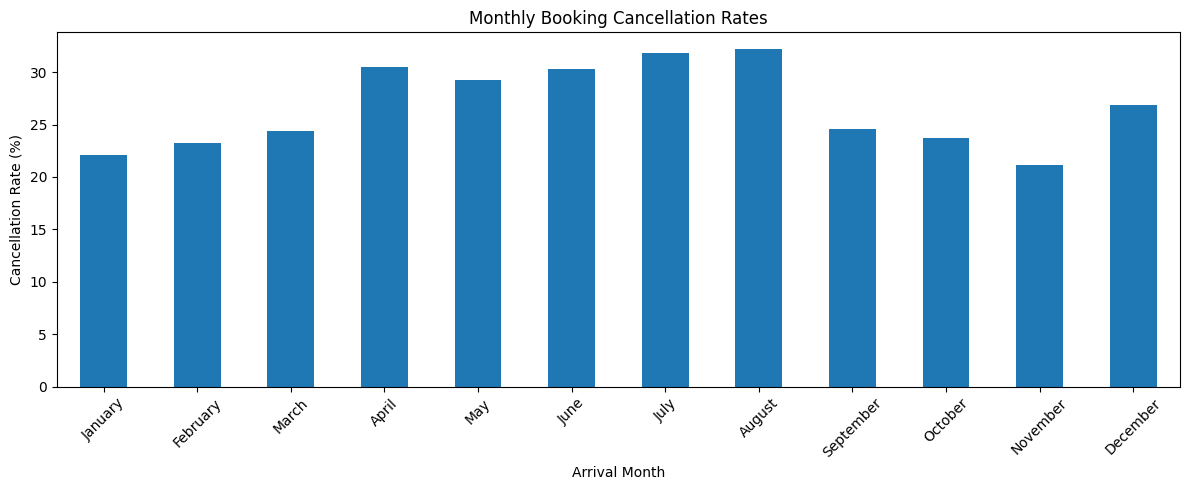

In [57]:
import matplotlib.pyplot as plt

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_cancellations = (
    df.groupby('arrival_date_month')['is_canceled']
    .mean()
    .mul(100)
    .reindex(month_order)
)

monthly_cancellations.plot(
    kind='bar',
    figsize=(12, 5),
    title='Monthly Booking Cancellation Rates',
    xlabel='Arrival Month',
    ylabel='Cancellation Rate (%)'
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

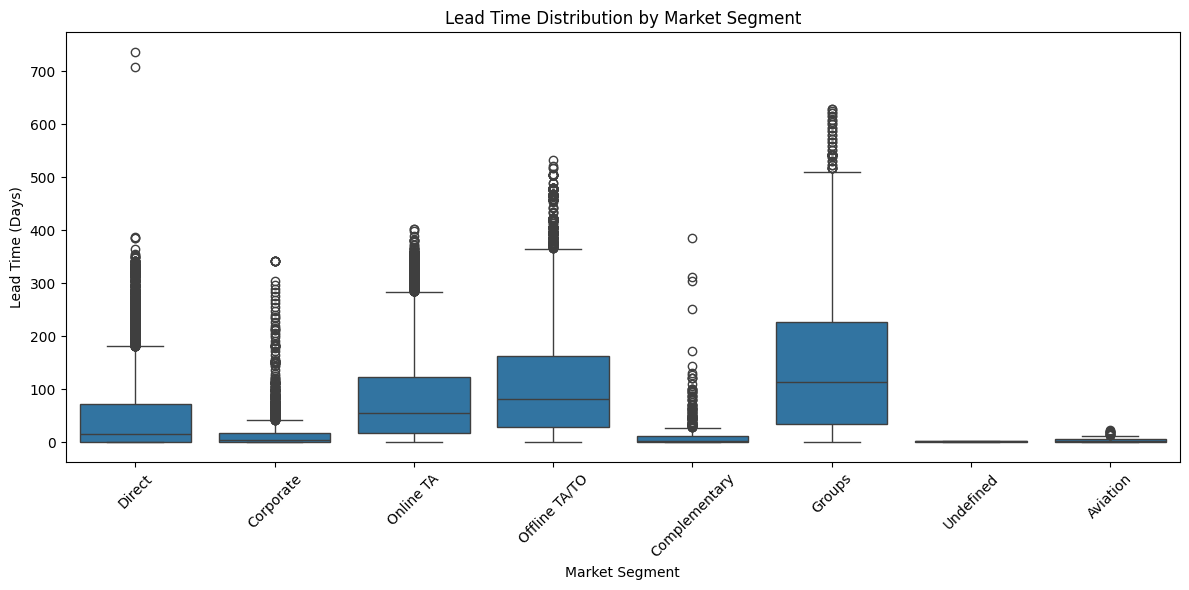

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='market_segment',
    y='lead_time'
)

plt.title('Lead Time Distribution by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Lead Time (Days)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()